In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn

# UTS Praktikum Kecerdasan Buatan — Template Notebook

Notebook ini mengikuti struktur soal pada PDF UTS: EDA, Linear Regression, serta K-NN (NIM ganjil) atau K-Means (NIM genap).

**Sebelum menjalankan:**
- Simpan dataset terkait di folder yang sama dengan notebook.
- Untuk Soal 2, periksa nama kolom pada `Sales_Data.csv` lalu sesuaikan variabel `PROMO_COL` dan `SALES_COL`.
- Pilih cabang Soal 3 sesuai NIM.
- Dataset `users_data_cleaned.pickle` dan `konsumen.csv` belum tersedia bersama soal; notebook ini tidak membuat-buat data tersebut.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# Pengaturan tampilan grafik
sns.set_theme(style="whitegrid")
%matplotlib inline

In [ ]:
# Soal 1
# 1. Load and preview the data
df1 = pd.read_pickle("users_data_cleaned.pickle")
print("Preview 5 Data Teratas:")
df1.head()

Preview 5 Data Teratas:


,user_id,number_transactions,total_amount_usd,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,term_deposit,date_joined,device
0,9231c446-cb16-4b2b-a7f7-ddfc8b25aaf6,3.0,2143.0,58,management,married,tertiary,False,True,False,None,261,1,-1,0,None,False,1998-08-23,mobile
1,bb92765a-08de-4963-b432-496524b39157,NaN,NaN,44,technician,single,secondary,False,True,False,None,151,1,-1,0,None,False,2008-07-15,desktop
2,573de577-49ef-42b9-83da-d3cfb817b5c1,2.0,2.0,33,entrepreneur,married,secondary,False,True,True,None,76,1,-1,0,None,False,2002-06-04,mobile
3,d6b66b9d-7c8f-4257-a682-e136f640b7e3,NaN,NaN,47,blue-collar,married,None,False,True,False,None,92,1,-1,0,None,False,1995-06-29,tablet
4,fade0b20-7594-4d9a-84cd-c02f79b1b526,1.0,1.0,33,None,single,None,False,False,False,None,198,1,-1,0,None,False,1995-08-01,mobile


In [4]:
# 2. Check the shape of the data
print("Shape Data (Baris, Kolom):", df1.shape)

Shape Data (Baris, Kolom): (45209, 19)


In [5]:
# 3. Check the data types
print("Tipe Data per Kolom:")
print(df1.dtypes)

Tipe Data per Kolom:
user_id                        object
number_transactions           float64
total_amount_usd              float64
age                             int64
job                            object
marital                        object
education                      object
default                          bool
housing                          bool
loan                             bool
contact                        object
duration                        int64
campaign                        int64
pdays                           int64
previous                        int64
poutcome                       object
term_deposit                     bool
date_joined            datetime64[ns]
device                         object
dtype: object


In [6]:
# 4. Check for correlations
print("Korelasi antar variabel numerik:")
df1.corr(numeric_only=True)

Korelasi antar variabel numerik:


,number_transactions,total_amount_usd,age,default,housing,loan,duration,campaign,pdays,previous,term_deposit
number_transactions,1.000000,-0.163409,-0.008813,0.138838,0.030429,0.075319,-0.017220,0.026431,-0.030751,-0.023046,-0.053390
total_amount_usd,-0.163409,1.000000,0.095839,-0.065390,-0.066857,-0.084526,0.022586,-0.017274,0.006435,0.016952,0.050785
age,-0.008813,0.095839,1.000000,-0.017875,-0.185552,-0.015641,-0.004645,0.004767,-0.023745,0.001297,0.025168
default,0.138838,-0.065390,-0.017875,1.000000,-0.006020,0.077232,-0.010017,0.016819,-0.029982,-0.018331,-0.022421
housing,0.030429,-0.066857,-0.185552,-0.006020,1.000000,0.041341,0.005041,-0.023583,0.124197,0.037087,-0.139161
loan,0.075319,-0.084526,-0.015641,0.077232,0.041341,1.000000,-0.012395,0.009972,-0.022762,-0.011048,-0.068193
duration,-0.017220,0.022586,-0.004645,-0.010017,0.005041,-0.012395,1.000000,-0.084551,-0.001549,0.001213,0.394549
campaign,0.026431,-0.017274,0.004767,0.016819,-0.023583,0.009972,-0.084551,1.000000,-0.088636,-0.032860,-0.073179
pdays,-0.030751,0.006435,-0.023745,-0.029982,0.124197,-0.022762,-0.001549,-0.088636,1.000000,0.454817,0.103616
previous,-0.023046,0.016952,0.001297,-0.018331,0.037087,-0.011048,0.001213,-0.032860,0.454817,1.000000,0.093232


In [7]:
# 5. Generate summary statistics for numerical data only
print("Ringkasan Statistik (Data Numerik):")
df1.describe()

Ringkasan Statistik (Data Numerik):


,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous,date_joined
count,35210.000000,35210.000000,45209.000000,45209.000000,45209.000000,45209.000000,45209.000000,45179
mean,3.977052,1369.417751,40.935853,258.153067,2.763897,40.199651,0.580349,1999-06-14 21:54:38.558622336
min,1.000000,-8019.000000,18.000000,0.000000,1.000000,-1.000000,0.000000,1988-01-01 00:00:00
25%,2.000000,73.000000,33.000000,103.000000,1.000000,-1.000000,0.000000,1993-09-18 00:00:00
50%,3.000000,451.000000,39.000000,180.000000,2.000000,-1.000000,0.000000,1999-06-11 00:00:00
75%,4.000000,1438.000000,48.000000,319.000000,3.000000,-1.000000,0.000000,2005-03-18 00:00:00
max,20.000000,102127.000000,95.000000,4918.000000,63.000000,871.000000,275.000000,2010-11-30 00:00:00
std,3.814329,3063.412688,10.618653,257.525446,3.098076,100.130586,2.303489,NaN


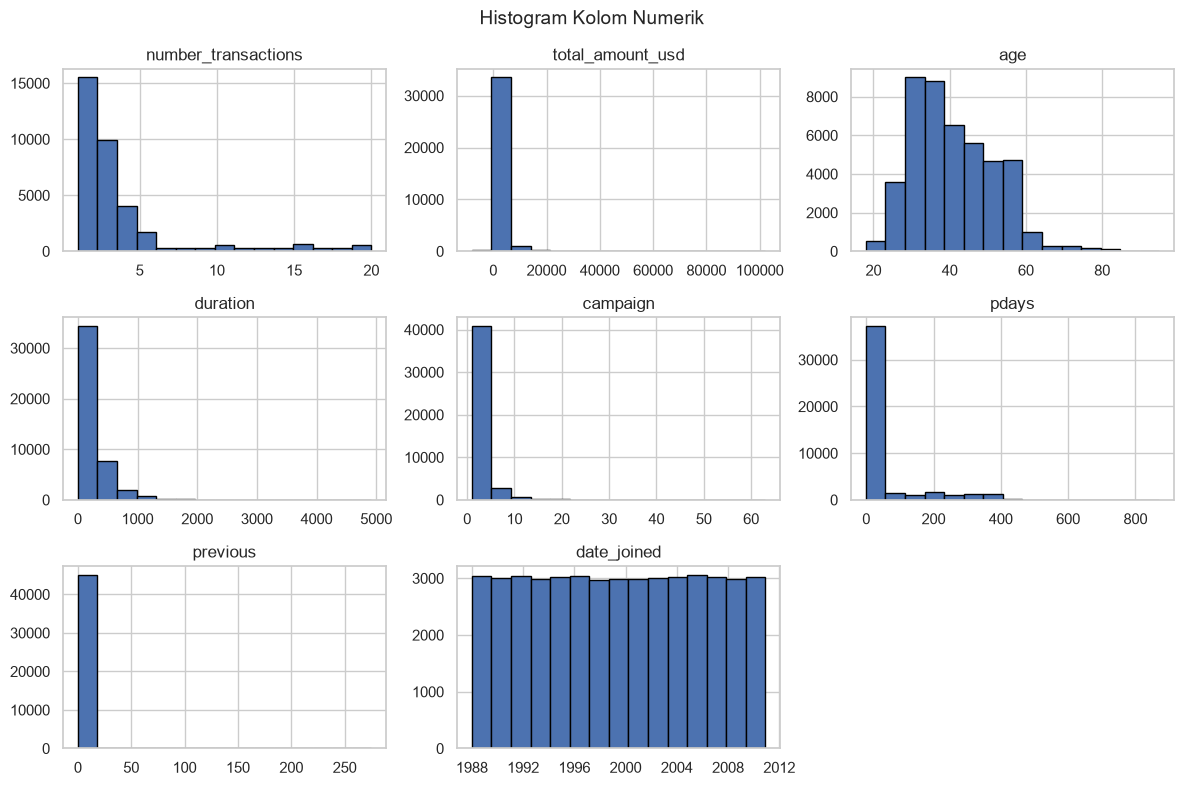

In [8]:
# 6. Plot Histograms for all numerical columns
df1.hist(figsize=(12, 8), bins=15, edgecolor="black")
plt.suptitle("Histogram Kolom Numerik", fontsize=14)
plt.tight_layout()
plt.show()

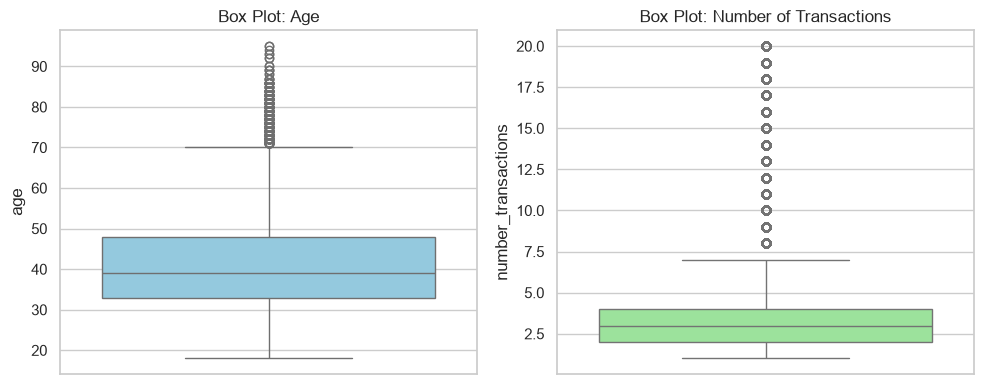

In [9]:
# 7. Generate a box plot for age dan number_transactions
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df1["age"], color="skyblue")
plt.title("Box Plot: Age")

plt.subplot(1, 2, 2)
sns.boxplot(y=df1["number_transactions"], color="lightgreen")
plt.title("Box Plot: Number of Transactions")

plt.tight_layout()
plt.show()

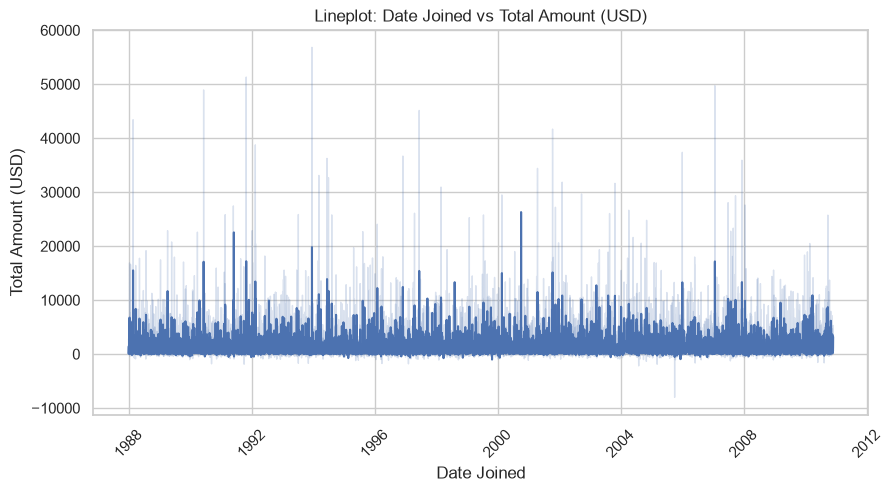

In [10]:
# 8. Generate a lineplot for date_joined to total_amount_usd
# Pastikan date_joined berformat datetime dan terurut
df1["date_joined"] = pd.to_datetime(df1["date_joined"])
df_sorted = df1.sort_values("date_joined")

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_sorted, x="date_joined", y="total_amount_usd")
plt.title("Lineplot: Date Joined vs Total Amount (USD)")
plt.xlabel("Date Joined")
plt.ylabel("Total Amount (USD)")
plt.xticks(rotation=45)
plt.show()

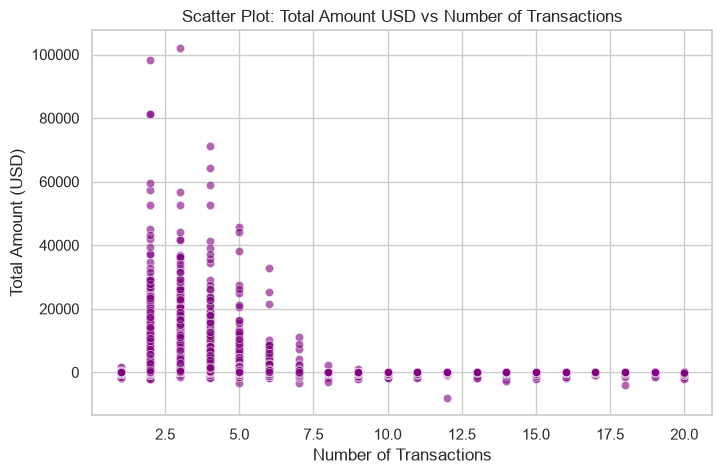

In [11]:
# 9. Generate scatter plots comparing total_amount_usd to number_transaction
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df1,
    x="number_transactions",
    y="total_amount_usd",
    alpha=0.6,
    color="purple",
)
plt.title("Scatter Plot: Total Amount USD vs Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Amount (USD)")
plt.show()

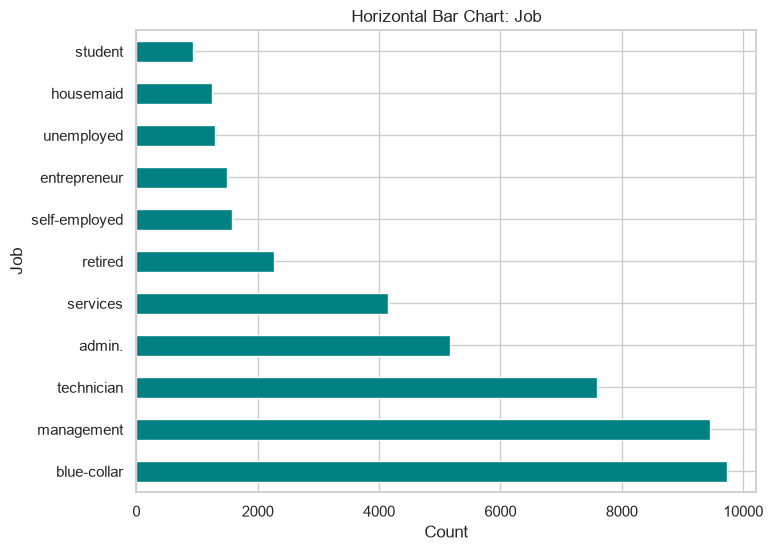

In [12]:
# 10. Generate Horizontal bar charts for job
plt.figure(figsize=(8, 6))
df1["job"].value_counts().plot(kind="barh", color="teal")
plt.title("Horizontal Bar Chart: Job")
plt.xlabel("Count")
plt.ylabel("Job")
plt.show()

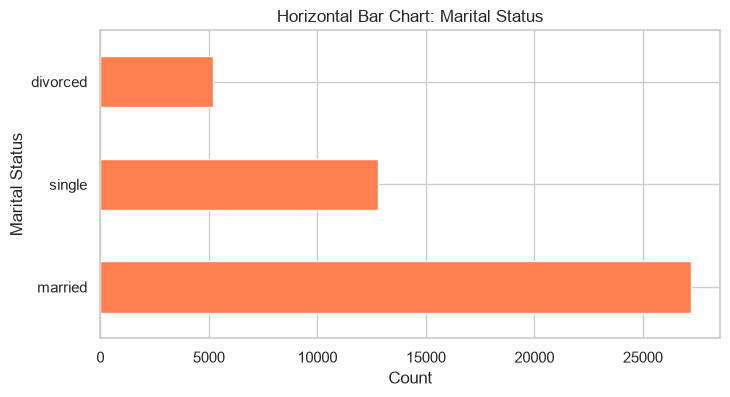

In [13]:
# 11. Generate Horizontal bar charts for marital
plt.figure(figsize=(8, 4))
df1["marital"].value_counts().plot(kind="barh", color="coral")
plt.title("Horizontal Bar Chart: Marital Status")
plt.xlabel("Count")
plt.ylabel("Marital Status")
plt.show()

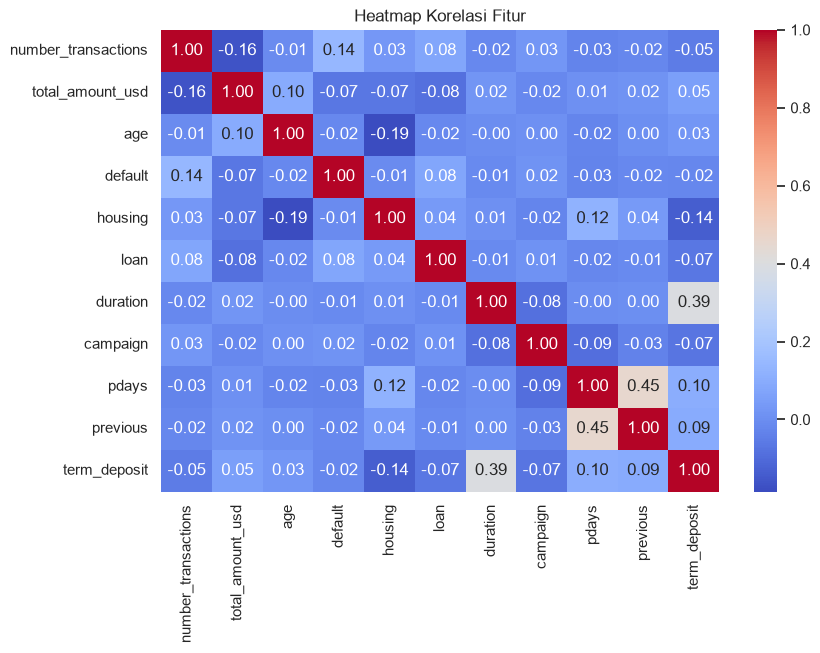

In [14]:
# 12. Generate a heatmap for future correlations (Feature Correlations)
plt.figure(figsize=(9, 6))
sns.heatmap(
    df1.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Heatmap Korelasi Fitur")
plt.show()

In [15]:
# 13. Identify Missing Values
print("Jumlah Missing Values per Kolom:")
print(df1.isnull().sum())

Jumlah Missing Values per Kolom:
user_id                    0
number_transactions     9999
total_amount_usd        9999
age                        0
job                      288
marital                    0
education               1857
default                    0
housing                    0
loan                       0
contact                13018
duration                   0
campaign                   0
pdays                      0
previous                   0
poutcome               36957
term_deposit               0
date_joined               30
device                    94
dtype: int64


In [19]:
# Soal 2
# 1.a Membaca file Sales_Data.csv 
df2 = pd.read_csv("Sales_Data.csv", sep=";")

# 1.b Menampilkan variable dalam dataset
print("Variabel/Kolom dalam dataset:")
print(df2.columns.tolist())
display(df2.head())

Variabel/Kolom dalam dataset:
['BiayaPromo', 'NilaiPenjualan']


,BiayaPromo,NilaiPenjualan
0,1500,90500
1,1800,89500
2,1900,105000
3,2050,102000
4,2050,90500


In [20]:
# Persiapan Fitur (X) dan Target (y)
# Catatan: Sesuaikan nama kolom jika ada perbedaan spasi/huruf besar-kecil pada dataset Anda
feature_col = [col for col in df2.columns if "promo" in col.lower()][0]
target_col = [
    col
    for col in df2.columns
    if "penjualan" in col.lower() or "sales" in col.lower()
][0]

X = df2[[feature_col]]
y = df2[target_col]

# 1.c Menampilkan data yang di-split (train: 80% & test: 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Ukuran X_train :", X_train.shape)
print("Ukuran X_test  :", X_test.shape)
print("\nPreview X_train:")
display(X_train.head())
print("Preview X_test:")
display(X_test.head())

Ukuran X_train : (16, 1)
Ukuran X_test  : (4, 1)

Preview X_train:


,BiayaPromo
8,3050
5,2100
11,3500
3,2050
18,4100


Preview X_test:


,BiayaPromo
0,1500
17,4000
15,3900
1,1800


In [21]:
# 1.d Memanggil LinearRegression() dan fitting model
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# 1.e Menampilkan hasil predict dari data test
y_pred_test = model_lr.predict(X_test)
df_eval = pd.DataFrame(
    {
        "Biaya Promo (X_test)": X_test.squeeze(),
        "Nilai Aktual": y_test,
        "Nilai Prediksi": y_pred_test,
    }
)
print("Hasil Prediksi Data Test:")
display(df_eval.head())

Hasil Prediksi Data Test:


,Biaya Promo (X_test),Nilai Aktual,Nilai Prediksi
0,1500,90500,79244.654151
17,4000,170500,199104.607971
15,3900,194500,194310.209818
1,1800,89500,93627.848610


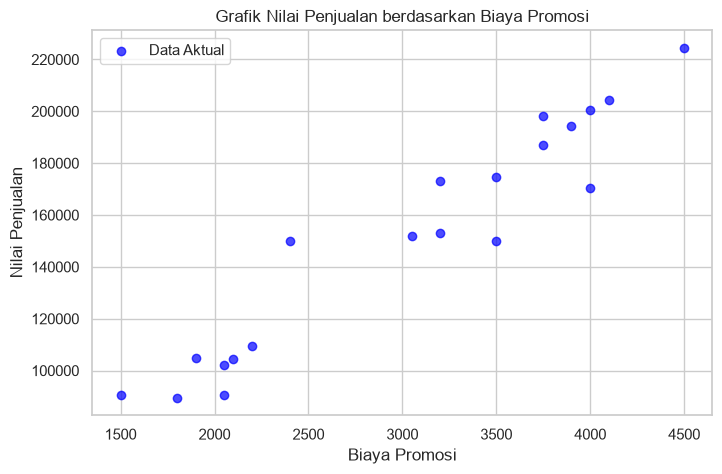

In [22]:
# 1.f Menampilkan Grafik Nilai Penjualan berdasarkan Biaya Promosi
plt.figure(figsize=(8, 5))
plt.scatter(
    df2[feature_col],
    df2[target_col],
    color="blue",
    alpha=0.7,
    label="Data Aktual",
)
plt.title("Grafik Nilai Penjualan berdasarkan Biaya Promosi")
plt.xlabel("Biaya Promosi")
plt.ylabel("Nilai Penjualan")
plt.legend()
plt.show()

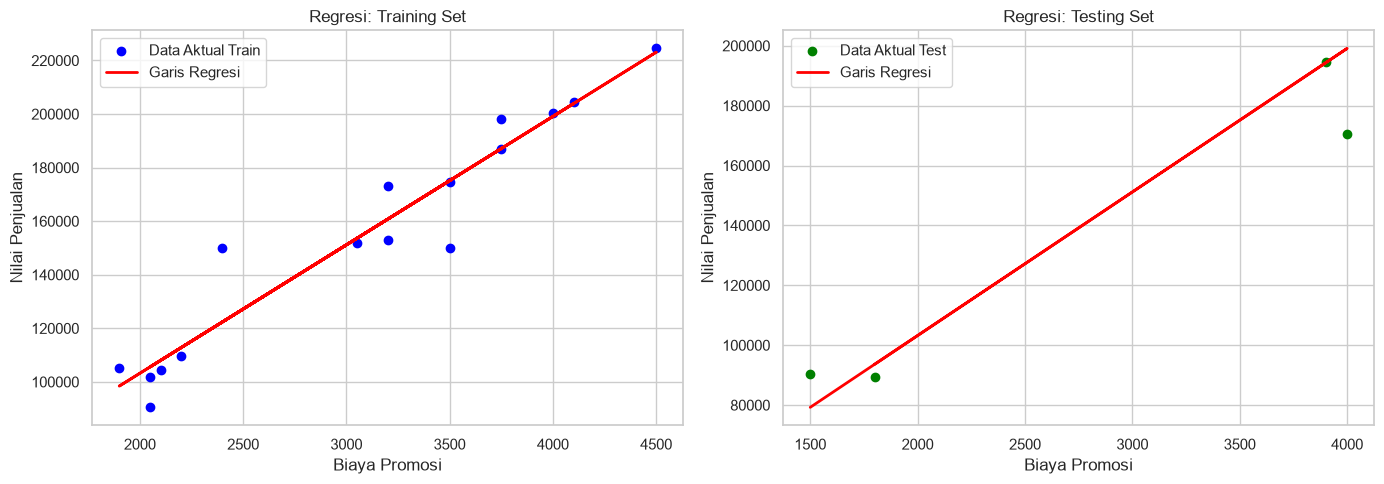

In [23]:
# 1.g Menampilkan Garis hasil prediksi (Train Set dan Test Set)
plt.figure(figsize=(14, 5))

# Plot Train Set
plt.subplot(1, 2, 1)
plt.scatter(X_train, y_train, color="blue", label="Data Aktual Train")
plt.plot(
    X_train,
    model_lr.predict(X_train),
    color="red",
    linewidth=2,
    label="Garis Regresi",
)
plt.title("Regresi: Training Set")
plt.xlabel("Biaya Promosi")
plt.ylabel("Nilai Penjualan")
plt.legend()

# Plot Test Set
plt.subplot(1, 2, 2)
plt.scatter(X_test, y_test, color="green", label="Data Aktual Test")
plt.plot(X_test, y_pred_test, color="red", linewidth=2, label="Garis Regresi")
plt.title("Regresi: Testing Set")
plt.xlabel("Biaya Promosi")
plt.ylabel("Nilai Penjualan")
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
# 2. Perhitungan Parameter Evaluasi
intercept = model_lr.intercept_
slope = model_lr.coef_[0]
r_squared = r2_score(y_test, y_pred_test)

print(f"a. Intercept : {intercept:.4f}")
print(f"b. Slope     : {slope:.4f}")
print(f"c. R-Square  : {r_squared:.4f}")

a. Intercept : 7328.6819
b. Slope     : 47.9440
c. R-Square  : 0.8912


In [ ]:
# Soal 3 ganjil
# 1. Membaca file pima-indians-diabetes.data.csv
cols = [
    "preg",
    "glukosa",
    "pres",
    "skin",
    "insulin",
    "BMI",
    "pedi",
    "age",
    "class",
]
try:
  # Cek jika file sudah memiliki header
  df3_ganjil = pd.read_csv("pima-indians-diabetes.data.csv")
  if set(cols).issubset(df3_ganjil.columns):
    pass
  else:
    df3_ganjil = pd.read_csv("pima-indians-diabetes.data.csv", names=cols)
except:
  df3_ganjil = pd.read_csv("pima-indians-diabetes.data.csv", names=cols)

# 2. Menampilkan sebanyak 8 row data teratas
print("8 Row Data Teratas:")
display(df3_ganjil.head(8))

8 Row Data Teratas:


,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0


In [26]:
# 3. Menampilkan data features dan label sebanyak 9 row teratas
X_ganjil = df3_ganjil.drop(columns=["class"])
y_ganjil = df3_ganjil["class"]

print("Features (9 baris teratas):")
display(X_ganjil.head(9))

print("Label (9 baris teratas):")
display(y_ganjil.head(9))

Features (9 baris teratas):


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
5,5,116,74,0,0,25.6,0.201,30
6,3,78,50,32,88,31.0,0.248,26
7,10,115,0,0,0,35.3,0.134,29
8,2,197,70,45,543,30.5,0.158,53


Label (9 baris teratas):


0    1
1    0
2    1
3    0
4    1
5    0
6    1
7    0
8    1
Name: class, dtype: int64

In [27]:
# 4. Menampilkan data yang di-split (train: 85% & test: 15%)
X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
    X_ganjil, y_ganjil, test_size=0.15, random_state=42
)

print(
    f"Ukuran Data Train: {X_train_g.shape[0]} baris (85%), Test:"
    f" {X_test_g.shape[0]} baris (15%)"
)
print("Preview X_train (5 teratas):")
display(X_train_g.head())
print("Preview X_test (5 teratas):")
display(X_test_g.head())

Ukuran Data Train: 652 baris (85%), Test: 116 baris (15%)
Preview X_train (5 teratas):


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
227,3,162,52,38,0,37.2,0.652,24
168,4,110,66,0,0,31.9,0.471,29
513,2,91,62,0,0,27.3,0.525,22
7,10,115,0,0,0,35.3,0.134,29
196,1,105,58,0,0,24.3,0.187,21


Preview X_test (5 teratas):


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
668,6,98,58,33,190,34.0,0.430,43
324,2,112,75,32,0,35.7,0.148,21
624,2,108,64,0,0,30.8,0.158,21
690,8,107,80,0,0,24.6,0.856,34
473,7,136,90,0,0,29.9,0.210,50


In [28]:
# 5. Memanggil KNeighborsClassifier dengan n_neighbors=5 dan Euclidean distance
knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn.fit(X_train_g, y_train_g)
y_pred_g = knn.predict(X_test_g)

# 6. Hitunglah score akurasinya
acc = accuracy_score(y_test_g, y_pred_g)
print(f"Skor Akurasi (k=5): {acc * 100:.2f}%")

Skor Akurasi (k=5): 67.24%


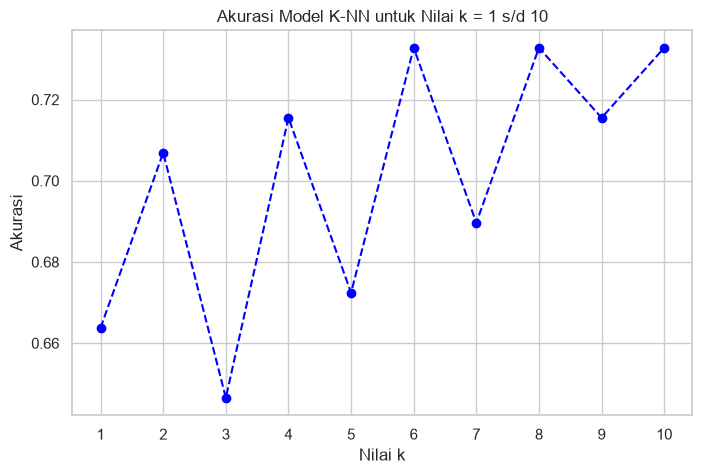

In [29]:
# 7. Grafik k terhadap nilai akurasi (maks k = 10)
k_values = list(range(1, 11))
accuracies = []

for k in k_values:
  model_k = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
  model_k.fit(X_train_g, y_train_g)
  pred_k = model_k.predict(X_test_g)
  accuracies.append(accuracy_score(y_test_g, pred_k))

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker="o", linestyle="--", color="blue")
plt.title("Akurasi Model K-NN untuk Nilai k = 1 s/d 10")
plt.xlabel("Nilai k")
plt.ylabel("Akurasi")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [32]:
# Soal 3 Genap
# 1. Membaca file konsumen.csv 
df3_genap = pd.read_csv("konsumen.csv", sep=";")

# 2. Menampilkan sebanyak 7 row data teratas
print("7 Row Data Teratas:")
display(df3_genap.head(7))

7 Row Data Teratas:


,No,Gaji,Pengeluaran
0,1,2500,1750
1,2,3800,4200
2,3,3900,3800
3,4,4350,5500
4,5,4400,3200
5,6,5500,5450
6,7,5600,5950


In [33]:
# 3. Menghapus kolom No
df3_genap = df3_genap.drop(columns=["No"])

# 4. Menampilkan 9 row data teratas
print("9 Row Data Teratas setelah kolom No dihapus:")
display(df3_genap.head(9))

9 Row Data Teratas setelah kolom No dihapus:


,Gaji,Pengeluaran
0,2500,1750
1,3800,4200
2,3900,3800
3,4350,5500
4,4400,3200
5,5500,5450
6,5600,5950
7,5750,4100
8,6850,6050


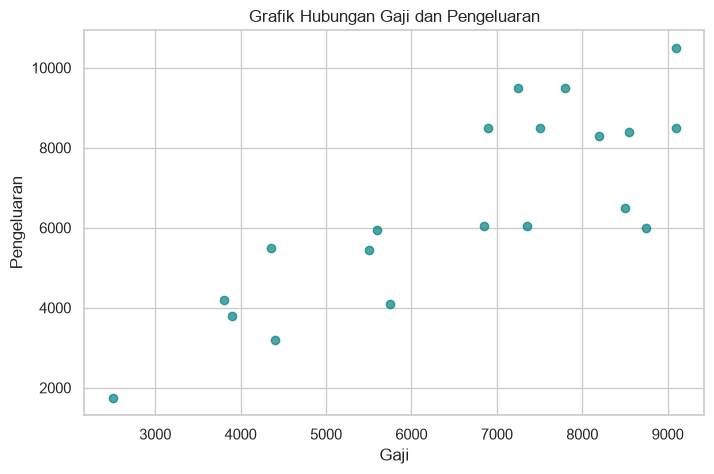

In [34]:
# 5. Menampilkan grafik hubungan gaji dan pengeluaran
plt.figure(figsize=(8, 5))
plt.scatter(
    df3_genap["Gaji"], df3_genap["Pengeluaran"], color="teal", alpha=0.7
)
plt.title("Grafik Hubungan Gaji dan Pengeluaran")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.show()

In [35]:
# 6. Gunakan 2 klaster (K-Means)
kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(df3_genap[["Gaji", "Pengeluaran"]])

# 7. Menampilkan nilai pusat klaster
centroids = kmeans.cluster_centers_
print("Nilai Pusat Klaster (Centroid):")
print(pd.DataFrame(centroids, columns=["Gaji", "Pengeluaran"]))

Nilai Pusat Klaster (Centroid):
     Gaji  Pengeluaran
0  4475.0      4243.75
1  7987.5      8025.00


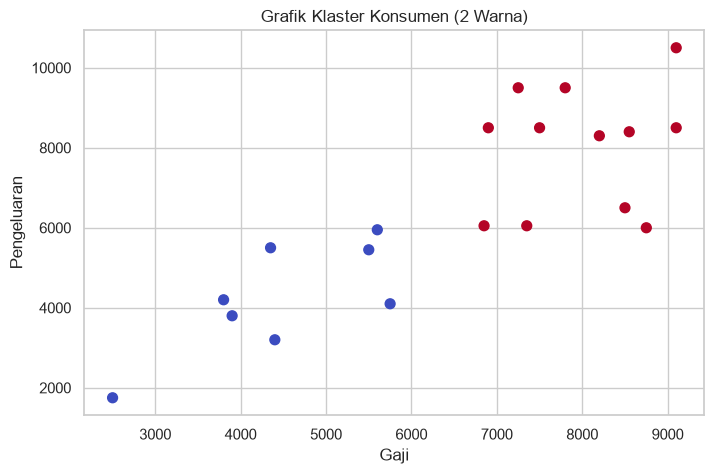

In [36]:
# 8. Grafik Konsumen yang memiliki 2 warna berbeda
plt.figure(figsize=(8, 5))
plt.scatter(
    df3_genap["Gaji"],
    df3_genap["Pengeluaran"],
    c=labels,
    cmap="coolwarm",
    s=50,
)
plt.title("Grafik Klaster Konsumen (2 Warna)")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.show()

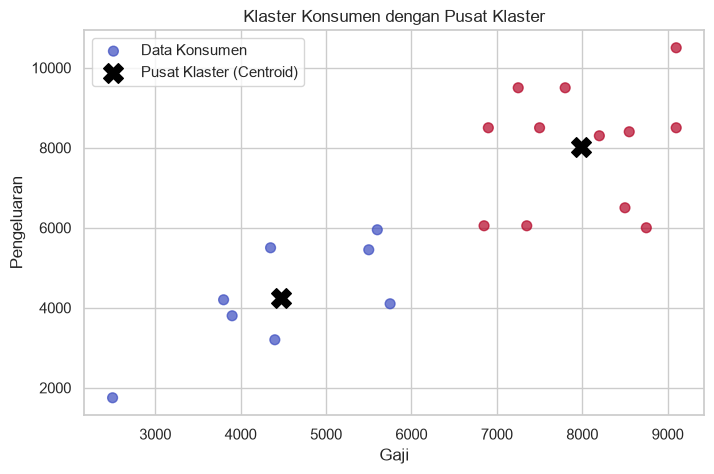

In [37]:
# 9. Grafik Konsumen dengan 2 warna berbeda berserta pusat klaster (Centroid)
plt.figure(figsize=(8, 5))
plt.scatter(
    df3_genap["Gaji"],
    df3_genap["Pengeluaran"],
    c=labels,
    cmap="coolwarm",
    s=50,
    alpha=0.7,
    label="Data Konsumen",
)
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c="black",
    s=200,
    marker="X",
    label="Pusat Klaster (Centroid)",
)
plt.title("Klaster Konsumen dengan Pusat Klaster")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.legend()
plt.show()